# 01 — Processing: raw collection → clean hourly dataset

**Input:** `data/goldpulse.sqlite3`, the raw tables written by the collector (`posts`, `price_ticks`).
**Output:** `data/clean/hourly_merged.parquet`, one row per UTC hour, the dataset Track B models on.

Every step here calls the functions in `processing/bucket.py`, so this notebook and the
committed pipeline cannot drift apart. The cleaning rules are documented at the top of that file
and in `docs/PITFALLS.md` (#9–#12).

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from processing import bucket

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)

## 1. Raw data, as collected

In [2]:
posts, prices = bucket.load_raw()
print(f"posts:       {len(posts):>5} rows  {posts.created_utc.min()} -> {posts.created_utc.max()}")
print(f"price_ticks: {len(prices):>5} rows  {prices.bucket_utc.min()} -> {prices.bucket_utc.max()}")
posts.groupby("subreddit").size().rename("posts").to_frame()

posts:        2479 rows  2026-09-06 05:56:43+00:00 -> 2026-10-05 15:53:45+00:00
price_ticks:   495 rows  2026-09-03 00:00:00+00:00 -> 2026-10-05 15:00:00+00:00


,posts
subreddit,
Gold,1161
Silverbugs,1301
investing,17


A sample of raw posts. Each post has a VADER sentiment score in [−1, 1] and an engagement number, which stays a placeholder (`engagement_stale = 1`) until Arctic Shift re-crawls the post (~36 h).

In [3]:
posts.sample(8, random_state=7)[
    ["post_id", "created_utc", "subreddit", "text", "sentiment", "engagement", "engagement_stale"]
].sort_values("created_utc")

,post_id,created_utc,subreddit,text,sentiment,engagement,engagement_stale
60,1wb0ucc,2026-09-08 20:54:44+00:00,Gold,Maybe a stupid question - need advice? Melt myself or wi...,0.9256,11.0,0
637,1wh4efq,2026-09-15 15:59:34+00:00,Silverbugs,First time in YEARS I can’t even remember the last time ...,0.5994,12.0,0
832,1wj00l0,2026-09-17 17:12:36+00:00,Gold,Picked this up for $2170 yesterday at LCS First slabbed ...,0.1901,95.0,0
855,1wj8gtz,2026-09-17 22:30:53+00:00,Silverbugs,All silver coins I have pulled out of circulation so far...,0.6908,39.0,0
1047,1wkwall,2026-09-19 20:12:23+00:00,Gold,Advice for repurposing my dad’s wedding band I’m most li...,-0.7797,30.0,0
1120,1wlh2xk,2026-09-20 13:26:47+00:00,Gold,Tiny fractional 8 carat gold ‘sovereign’ Marked .333 8 c...,0.0000,37.0,0
1797,1wsf1m9,2026-09-28 13:45:30+00:00,Silverbugs,Running the stops,-0.1531,0.0,0
2296,1wwpnnp,2026-10-03 15:13:05+00:00,Gold,Please rate my goldback,0.3182,1.0,0


Raw price ticks: the GC=F (COMEX gold futures) Open at the top of each hour the market traded. This table was already rebuilt from Yahoo hourly bars on Oct 5 (`backfill_price.py`; see `docs/PITFALLS.md` #2–#3). `collected_at` shows which rows came from the live feed and which from the backfill.

In [4]:
prices.sort_values('bucket_utc').head(6)

,bucket_utc,xau_usd,collected_at
2,2026-09-03 00:00:00+00:00,4431.200195,2026-10-05T15:24:22.412460+00:00
3,2026-09-03 01:00:00+00:00,4440.799805,2026-10-05T15:24:22.412460+00:00
4,2026-09-03 02:00:00+00:00,4455.200195,2026-10-05T15:24:22.412460+00:00
5,2026-09-03 03:00:00+00:00,4466.000000,2026-10-05T15:24:22.412460+00:00
6,2026-09-03 04:00:00+00:00,4477.299805,2026-10-05T15:24:22.412460+00:00
7,2026-09-03 05:00:00+00:00,4483.100098,2026-10-05T15:24:22.412460+00:00


## 2. Raw-data quality issues the pipeline has to handle

In [5]:
in_window = posts[posts.created_utc >= bucket.WINDOW_START]
norm = in_window.text.map(bucket.normalize_text)
dup_groups = in_window[norm.duplicated(keep=False)].assign(norm=norm).groupby("norm")
stale = int(in_window.engagement_stale.sum())
print(f"posts in window (from {bucket.WINDOW_START}): {len(in_window)}")
print(f"identical-text groups:                 {dup_groups.ngroups}  ({dup_groups.size().sum()} posts)")
print(f"posts with placeholder engagement:     {stale}  ({stale / len(in_window):.1%})")
hours_total = int((prices.bucket_utc.max() - prices.bucket_utc.min()) / pd.Timedelta("1h")) + 1
print(f"price hours present / calendar hours:  {len(prices)} / {hours_total}  (market closed nights/weekends)")

posts in window (from 2026-09-08): 2477
identical-text groups:                 62  (133 posts)
posts with placeholder engagement:     142  (5.7%)
price hours present / calendar hours:  495 / 784  (market closed nights/weekends)


An example of each kind of duplicate. A **cross-post** (same story, two subreddits, minutes apart) is a real duplicate. A **generic title** posted days apart by different people is not.

In [6]:
example = (in_window.assign(norm=norm)
           .loc[lambda d: d.norm.duplicated(keep=False)]
           .sort_values("created_utc")
           .groupby("norm")
           .filter(lambda g: g.subreddit.nunique() > 1)
           .head(2))
example[["post_id", "created_utc", "subreddit", "text"]]

,post_id,created_utc,subreddit,text
375,1wekc39,2026-09-12 18:33:54+00:00,Silverbugs,I Used to Not Like Slabs… Now I Need More
371,1wekcvf,2026-09-12 18:34:42+00:00,Gold,I Used to Not Like Slabs… Now I Need More


## 3. Step 1: de-duplicate
Drop a post if its normalized text (lowercased, URLs and punctuation stripped) matches an earlier
post **within 24 h**, keeping the earliest copy.

In [7]:
end = bucket.default_end(posts)
start = bucket._utc_hour(bucket.WINDOW_START)
window = posts[(posts.created_utc >= start) & (posts.created_utc < end + pd.Timedelta(hours=1))]
deduped = bucket.dedupe_posts(window)
print(f"window {start} -> {end}")
print(f"{len(window)} posts -> {len(deduped)} after de-duplication ({len(window) - len(deduped)} dropped)")

window 2026-09-08 00:00:00+00:00 -> 2026-10-05 15:00:00+00:00
2477 posts -> 2419 after de-duplication (58 dropped)


## 4. Step 2: aggregate to the hour
`bullish_ratio` and `bearish_ratio` use VADER's ±0.05 neutral band. `mean_engagement` averages
**settled rows only**; `stale_share` records how much of each hour was excluded.

In [8]:
hourly_posts = bucket.aggregate_hourly(deduped)
hourly_posts.head(8)

,post_count,mean_sentiment,bullish_ratio,bearish_ratio,mean_engagement,stale_share
bucket_utc,,,,,,
2026-09-08 00:00:00+00:00,1,0.931900,1.000000,0.000000,30.0,0.0
2026-09-08 01:00:00+00:00,2,0.511750,1.000000,0.000000,70.0,0.0
2026-09-08 02:00:00+00:00,3,-0.229567,0.333333,0.333333,46.0,0.0
2026-09-08 03:00:00+00:00,1,0.734500,1.000000,0.000000,103.0,0.0
2026-09-08 04:00:00+00:00,2,0.745700,1.000000,0.000000,142.0,0.0
2026-09-08 06:00:00+00:00,1,0.077200,1.000000,0.000000,1.0,0.0
2026-09-08 08:00:00+00:00,2,0.653250,1.000000,0.000000,1.0,0.0
2026-09-08 09:00:00+00:00,2,0.828600,1.000000,0.000000,122.0,0.0


## 5. Step 3: full hourly grid, merge prices, sparse-hour rule
* Every UTC hour in the window gets a row.
* Sentiment columns are **forward-filled** over hours with no posts, **never back-filled**
  (that would leak the future). `post_count` is 0 there and `had_posts` is False.
* `xau_usd` is **never filled**: closed-market hours stay NaN, flagged by `market_open`.
  A carried-forward price would look like "no change" to the model.

In [9]:
clean = bucket.build_hourly(deduped, prices, start, end)
clean.head(10)

,post_count,mean_sentiment,bullish_ratio,bearish_ratio,mean_engagement,stale_share,had_posts,xau_usd,market_open
bucket_utc,,,,,,,,,
2026-09-08 00:00:00+00:00,1,0.931900,1.000000,0.000000,30.0,0.0,True,NaN,False
2026-09-08 01:00:00+00:00,2,0.511750,1.000000,0.000000,70.0,0.0,True,NaN,False
2026-09-08 02:00:00+00:00,3,-0.229567,0.333333,0.333333,46.0,0.0,True,NaN,False
2026-09-08 03:00:00+00:00,1,0.734500,1.000000,0.000000,103.0,0.0,True,NaN,False
2026-09-08 04:00:00+00:00,2,0.745700,1.000000,0.000000,142.0,0.0,True,4483.500000,True
2026-09-08 05:00:00+00:00,0,0.745700,1.000000,0.000000,NaN,NaN,False,4481.700195,True
2026-09-08 06:00:00+00:00,1,0.077200,1.000000,0.000000,1.0,0.0,True,4464.399902,True
2026-09-08 07:00:00+00:00,0,0.077200,1.000000,0.000000,NaN,NaN,False,4448.600098,True
2026-09-08 08:00:00+00:00,2,0.653250,1.000000,0.000000,1.0,0.0,True,4436.600098,True


Around a trading hour with **no posts**: sentiment is carried forward, `post_count` is 0, and the price is still present.

In [10]:
empty = clean.index[(~clean.had_posts) & clean.market_open][0]
clean.loc[empty - pd.Timedelta(hours=2): empty + pd.Timedelta(hours=2)]

,post_count,mean_sentiment,bullish_ratio,bearish_ratio,mean_engagement,stale_share,had_posts,xau_usd,market_open
bucket_utc,,,,,,,,,
2026-09-08 03:00:00+00:00,1,0.7345,1.0,0.0,103.0,0.0,True,NaN,False
2026-09-08 04:00:00+00:00,2,0.7457,1.0,0.0,142.0,0.0,True,4483.500000,True
2026-09-08 05:00:00+00:00,0,0.7457,1.0,0.0,NaN,NaN,False,4481.700195,True
2026-09-08 06:00:00+00:00,1,0.0772,1.0,0.0,1.0,0.0,True,4464.399902,True
2026-09-08 07:00:00+00:00,0,0.0772,1.0,0.0,NaN,NaN,False,4448.600098,True


Around the **weekend close**: the price goes NaN while the posts keep coming.

In [11]:
closed = clean.index[(clean.market_open.shift(1, fill_value=False)) & (~clean.market_open)
                     & (clean.index.dayofweek == 4)][0]
clean.loc[closed - pd.Timedelta(hours=2): closed + pd.Timedelta(hours=3)]

,post_count,mean_sentiment,bullish_ratio,bearish_ratio,mean_engagement,stale_share,had_posts,xau_usd,market_open
bucket_utc,,,,,,,,,
2026-09-11 19:00:00+00:00,4,0.479550,0.750000,0.00,124.750000,0.0,True,4389.299805,True
2026-09-11 20:00:00+00:00,7,0.392043,0.714286,0.00,184.142857,0.0,True,4391.000000,True
2026-09-11 21:00:00+00:00,5,0.171520,0.600000,0.20,38.000000,0.0,True,NaN,False
2026-09-11 22:00:00+00:00,8,0.143637,0.375000,0.25,49.875000,0.0,True,NaN,False
2026-09-11 23:00:00+00:00,5,0.327660,0.600000,0.20,155.400000,0.0,True,NaN,False
2026-09-12 00:00:00+00:00,4,0.317050,0.750000,0.00,101.500000,0.0,True,NaN,False


## 6. Checks

In [12]:
gaps = clean.index.to_series().diff().dropna()
assert (gaps == pd.Timedelta("1h")).all(), "grid has a missing or repeated hour"
assert clean.post_count.sum() == len(deduped), "post_count doesn't add up"
assert (clean.market_open == clean.xau_usd.notna()).all()
first_post_hour = clean.index[clean.had_posts.argmax()]
assert clean.loc[:first_post_hour].iloc[:-1].mean_sentiment.isna().all(), "back-fill detected"
filled = clean[~clean.had_posts]
assert (filled.post_count == 0).all()
print("all checks passed")

all checks passed


## 7. Before → after

In [13]:
summary = pd.DataFrame({
    "raw": [len(posts), len(prices), "irregular (post timestamps)", stale],
    "clean": [int(clean.post_count.sum()), int(clean.market_open.sum()),
              f"{len(clean)} hourly rows, none missing",
              f"excluded from mean_engagement ({clean.stale_share.mean():.1%} of hours' posts on average)"],
}, index=["posts", "price hours", "time axis", "placeholder engagement"])
summary

,raw,clean
posts,2479,2419
price hours,495,450
time axis,irregular (post timestamps),"664 hourly rows, none missing"
placeholder engagement,142,excluded from mean_engagement (5.7% of hours' posts on a...


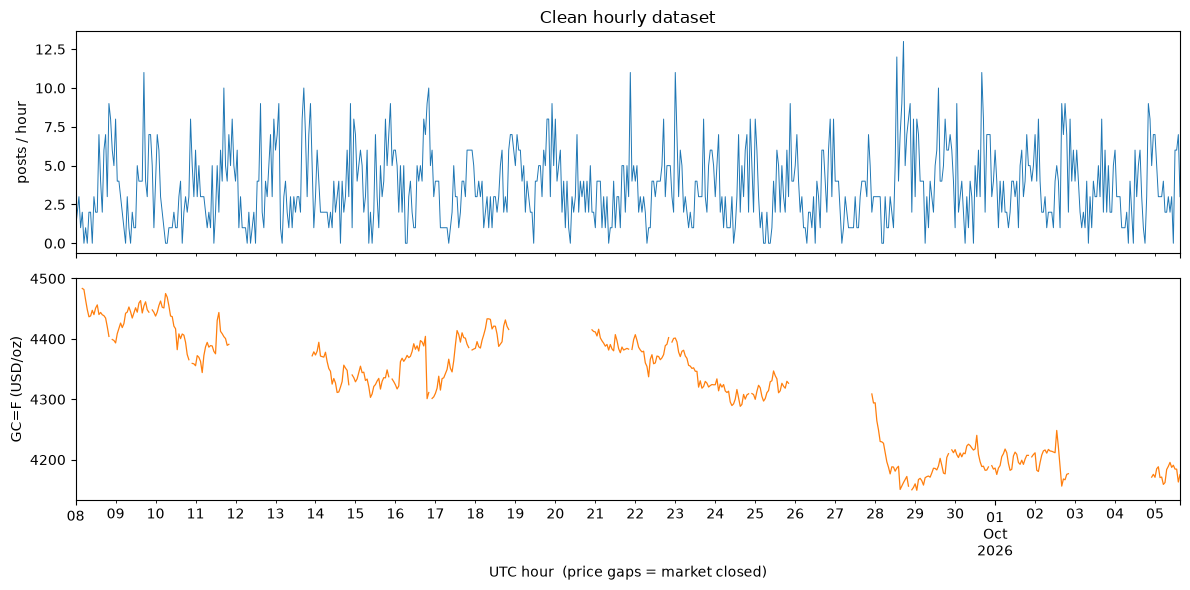

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
clean.post_count.plot(ax=ax1, lw=0.7, color="tab:blue")
ax1.set_ylabel("posts / hour")
ax1.set_title("Clean hourly dataset")
clean.xau_usd.plot(ax=ax2, lw=0.9, color="tab:orange")
ax2.set_ylabel("GC=F (USD/oz)")
ax2.set_xlabel("UTC hour  (price gaps = market closed)")
plt.tight_layout()

## 8. Save
`bucket.run()` is what `python -m processing.bucket` runs. It must reproduce the step-by-step frame exactly.

In [15]:
saved, info = bucket.run()
pd.testing.assert_frame_equal(saved, clean, check_freq=False)
print(info["output"])
pd.read_parquet(bucket.OUTPUT_PATH).info()

C:\Users\USER\Desktop\GoldPulse-repo\data\clean\hourly_merged.parquet
<class 'pandas.DataFrame'>
DatetimeIndex: 664 entries, 2026-09-08 00:00:00+00:00 to 2026-10-05 15:00:00+00:00
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_count       664 non-null    int64  
 1   mean_sentiment   664 non-null    float64
 2   bullish_ratio    664 non-null    float64
 3   bearish_ratio    664 non-null    float64
 4   mean_engagement  588 non-null    float64
 5   stale_share      623 non-null    float64
 6   had_posts        664 non-null    bool   
 7   xau_usd          450 non-null    float64
 8   market_open      664 non-null    bool   
dtypes: bool(2), float64(6), int64(1)
memory usage: 42.8 KB
